In [1]:
# ============================================================
# CELL 1 (06_evaluation_extremes): Extremes at event level (reads from disk; nothing is re-tuned)
# What it does:
#   0) loads outputs/preds_headline.parquet (held-out station, 2011-2023, plain LOSO outputs) and
#      the station-specific wet-day P95 thresholds from eda_decisions.json; puts each output on a
#      full daily calendar 2011-2023 per station
#   A) annual maximum day (station-years with >= 300 valid days): ratio of mean simulated to mean
#      observed annual maximum, correlation of annual maxima across years (stations with >= 5 years),
#      and the share of station-years where the simulated annual maximum falls on the same day,
#      within +-1 day and within +-3 days of the observed one
#   B) the 10 largest observed days per station: median simulated/observed ratio, share >= the
#      station's wet-day P95 (same day and within +-1 day), share >= 50 mm, and share inside the
#      output's own top 5% of days (chance level 5%)
#   C) at the top 5% of the output's own days: precision (share with observed >= P95), the base rate
#      of observed P95 days, and recall (share of observed P95 days that land in the top 5%)
#   D) per-station table of the +-1 day P95 hit share; saves outputs/extremes_events.csv
# ============================================================
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 60)

ROOT = Path.cwd().parent
PROC = ROOT / "data" / "processed"
OUT = ROOT / "outputs"

with open(PROC / "eda_decisions.json") as f:
    dec = json.load(f)
THR = dec["extreme_thresholds_mm"]

P = pd.read_parquet(OUT / "preds_headline.parquet")
P["date"] = pd.to_datetime(P["date"])
LABS = {"CHIRPS": "raw CHIRPS",
        "QMrel": "QM rel CHIRPS/loso",
        "FG raw": "XGB lean + far gauges (raw)/loso",
        "FG+QM": "XGB lean + far gauges (+QM)/loso"}
cal = pd.date_range("2011-01-01", "2023-12-31")

def wide(label, col):
    return (P[P["label"] == label].pivot(index="date", columns="station", values=col)
            .reindex(cal))

O = wide(LABS["CHIRPS"], "obs")
W = {k: wide(v, "sim") for k, v in LABS.items()}
stations = list(O.columns)
print("Stations:", stations, "| days:", len(cal))

# --- A) annual maximum day ---
rowsA = []
for k, w in W.items():
    ratio, corr = [], []
    n_sy = d0 = d1 = d3 = 0
    for st in stations:
        om, sm = [], []
        for y in range(2011, 2024):
            oy = O[st][O.index.year == y]
            sy = w[st][w.index.year == y]
            if oy.notna().sum() < 300 or sy.notna().sum() < 300:
                continue
            om.append(oy.max())
            sm.append(sy.max())
            dd = abs((sy.idxmax() - oy.idxmax()).days)
            n_sy += 1
            d0 += dd == 0
            d1 += dd <= 1
            d3 += dd <= 3
        if len(om) >= 5:
            ratio.append(np.mean(sm) / np.mean(om))
            corr.append(np.corrcoef(om, sm)[0, 1])
    rowsA.append({"output": k, "annual-max ratio (sim/obs)": round(np.mean(ratio), 2),
                  "r across years": round(np.mean(corr), 2), "station-years": n_sy,
                  "same day %": round(100 * d0 / n_sy, 1), "within 1 day %": round(100 * d1 / n_sy, 1),
                  "within 3 days %": round(100 * d3 / n_sy, 1)})
print("\nA) Annual maximum day, 2011-2023 (chance level for 'within 3 days' is about 2% to 6%)")
print(pd.DataFrame(rowsA).to_string(index=False))

# --- B) the 10 largest observed days per station ---
rowsB, events = [], []
for st in stations:
    o = O[st].dropna()
    top = o.nlargest(10).index
    p95 = THR[st]["P95_wet"]
    ev = pd.DataFrame({"station": st, "date": top, "obs": o[top].to_numpy()})
    for k, w in W.items():
        s = w[st]
        sv = s.reindex(top)
        s1 = pd.concat([s.shift(1), s, s.shift(-1)], axis=1).max(axis=1).reindex(top)
        q95 = s.quantile(0.95)
        rowsB.append({"output": k, "station": st,
                      "median sim/obs": float((sv / o[top]).median()),
                      "hit P95 same day": float((sv >= p95).mean()),
                      "hit P95 +-1 day": float((s1 >= p95).mean()),
                      "hit 50 mm": float((sv >= 50).mean()),
                      "in output top 5%": float((sv >= q95).mean())})
        ev[k] = sv.to_numpy()
    events.append(ev)
resB = pd.DataFrame(rowsB)
tB = resB.groupby("output")[["median sim/obs", "hit P95 same day", "hit P95 +-1 day",
                             "hit 50 mm", "in output top 5%"]].mean().loc[list(LABS)].round(2)
print("\nB) The 10 largest observed days per station (70 events); means over stations")
print(tB.to_string())

# --- C) precision and recall at the output's own top 5% ---
rowsC = []
for k, w in W.items():
    prec, base, rec = [], [], []
    for st in stations:
        both = pd.DataFrame({"o": O[st], "s": w[st]}).dropna()
        p95 = THR[st]["P95_wet"]
        top = both["s"] >= both["s"].quantile(0.95)
        hit = both["o"] >= p95
        prec.append(hit[top].mean())
        base.append(hit.mean())
        rec.append(top[hit].mean())
    rowsC.append({"output": k, "precision at top 5%": round(np.mean(prec), 3),
                  "base rate of P95 days": round(np.mean(base), 3),
                  "recall (P95 days in top 5%)": round(np.mean(rec), 3)})
print("\nC) Output's own top 5% of days against observed wet-day-P95 days (means over stations)")
print(pd.DataFrame(rowsC).to_string(index=False))

# --- D) per-station table and saved events ---
print("\nD) Share of the 10 largest observed days where the output reaches the station's P95 within +-1 day")
print(resB.pivot_table(index="station", columns="output", values="hit P95 +-1 day")
      .loc[stations, list(LABS)].round(2).to_string())
pd.concat(events, ignore_index=True).round(1).to_csv(OUT / "extremes_events.csv", index=False)
print("\nSaved: outputs/extremes_events.csv")

Stations: ['Bandipur', 'Damauli', 'Kunchha', 'Lamachaur', 'Lumle', 'Pokhara Airport', 'Sikles'] | days: 4748

A) Annual maximum day, 2011-2023 (chance level for 'within 3 days' is about 2% to 6%)
output  annual-max ratio (sim/obs)  r across years  station-years  same day %  within 1 day %  within 3 days %
CHIRPS                        0.69            0.22             89         7.9            10.1             12.4
 QMrel                        1.19            0.18             89         6.7             9.0             11.2
FG raw                        0.43            0.37             89         7.9            16.9             19.1
 FG+QM                        1.28            0.24             89         7.9            14.6             16.9

B) The 10 largest observed days per station (70 events); means over stations
        median sim/obs  hit P95 same day  hit P95 +-1 day  hit 50 mm  in output top 5%
output                                                                              

In [2]:
# ============================================================
# CELL 2 (06_evaluation_extremes): Chance level for event timing, ranking of heavy days, SHAP
# What it does:
#   A1) annual-maximum timing against a shuffled-year chance level: for each output (raw CHIRPS,
#       normalised mapping, far-gauge model raw and +QM) and station, compares the day of year of the
#       simulated annual maximum in year y with the observed one in the same year (matched) and in every
#       other year (shuffled); share within 0, 1 and 3 days; station-years with >= 300 valid days
#   A2) the 10 largest observed days per station: how many fall in the output's own top 5% of days, for
#       raw CHIRPS, the lean model (+QM) and the far-gauge model (+QM); chance = 0.5 per station
#   B)  SHAP for the frozen far-gauge model trained on all 7 stations (depth 3, min child weight 100,
#       Tweedie 1.5; same training as the Chapakot model), on 20,000 random 2011-2023 rows. Prints a
#       check that SHAP values add up to the model's raw output, the importance of each feature
#       (mean |SHAP|, log scale; share of the total; Spearman direction), a grouped summary, and the same
#       grouped summary for the rows the model puts in its own top 5%
# Needs outputs/preds_headline.parquet, the model table and rain_final.parquet from earlier notebooks.
# ============================================================
import importlib
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xgboost as xgb

warnings.filterwarnings("ignore")
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 60)

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import metrics, splits
import model_utils as mu
import far_gauge as far
importlib.reload(mu)
importlib.reload(far)

OUT = ROOT / "outputs"
P = pd.read_parquet(OUT / "preds_headline.parquet")
P["date"] = pd.to_datetime(P["date"])
cal = pd.date_range("2011-01-01", "2023-12-31")
LABS = {"CHIRPS": "raw CHIRPS", "QMrel": "QM rel CHIRPS/loso",
        "FG raw": "XGB lean + far gauges (raw)/loso", "FG+QM": "XGB lean + far gauges (+QM)/loso",
        "Lean+QM": "XGB lean (+QM)/loso"}

def wide(label, col):
    return P[P["label"] == label].pivot(index="date", columns="station", values=col).reindex(cal)

O = wide(LABS["CHIRPS"], "obs")
W = {k: wide(v, "sim") for k, v in LABS.items()}
stations = list(O.columns)

# --- A1) timing of the annual maximum vs shuffled years ---
rows = []
for k in ("CHIRPS", "QMrel", "FG raw", "FG+QM"):
    mh, sh = {0: 0, 1: 0, 3: 0}, {0: 0, 1: 0, 3: 0}
    nm = ns = 0
    for st in stations:
        do, ds = {}, {}
        for y in range(2011, 2024):
            oy = O[st][O.index.year == y]
            sy = W[k][st][W[k].index.year == y]
            if oy.notna().sum() < 300 or sy.notna().sum() < 300:
                continue
            do[y], ds[y] = oy.idxmax().dayofyear, sy.idxmax().dayofyear
        ys = list(do)
        for y in ys:
            for y2 in ys:
                d = abs(ds[y] - do[y2])
                if y == y2:
                    nm += 1
                    for t in mh:
                        mh[t] += d <= t
                else:
                    ns += 1
                    for t in sh:
                        sh[t] += d <= t
    r = {"output": k, "station-years": nm}
    for t in (0, 1, 3):
        r[f"matched +-{t}d %"] = round(100 * mh[t] / nm, 1)
        r[f"shuffled +-{t}d %"] = round(100 * sh[t] / ns, 1)
    rows.append(r)
print("A1) Day of the annual maximum, 2011-2023: matched years vs shuffled years (empirical chance level)")
print(pd.DataFrame(rows).to_string(index=False))

# --- A2) ranking of the 10 largest observed days per station ---
cnt = {}
for k in ("CHIRPS", "Lean+QM", "FG+QM"):
    c = {}
    for st in stations:
        top = O[st].dropna().nlargest(10).index
        s = W[k][st]
        c[st] = int((s.reindex(top) >= s.quantile(0.95)).sum())
    cnt[k] = c
t2 = pd.DataFrame(cnt).loc[stations]
t2.loc["TOTAL of 70"] = t2.sum()
print("\nA2) Number of the 10 largest observed days that fall in the output's own top 5% of days (chance: 0.5 per station)")
print(t2.to_string())

# --- B) SHAP ---
D = mu.Data(ROOT)
LEAN = mu.CHIRPS_F + mu.ERA_ATM
PARAMS = dict(mu.BASE_PARAMS, max_depth=3, min_child_weight=100, tweedie_variance_power=1.5)
rain = pd.read_parquet(D.proc / "rain_final.parquet")[D.stations]
X_lean = D.X[:, [D.feats.index(c) for c in LEAN]]
NB = far.build_far_features(D, rain, D.stations)
X = np.hstack([X_lean, NB])
names = LEAN + far.NB_COLS

fold = {"held_out": "Chapakot", "train": D.stations, "scheme": "app"}
m = splits.fold_masks(D.valid, fold, D.train_end)
i_fit, i_val, i_all = m["train"] & D.early_fit, m["train"] & D.val_block, m["train"]
mdl = xgb.XGBRegressor(n_estimators=1500, early_stopping_rounds=50, **PARAMS)
mdl.fit(X[i_fit], D.yrel[i_fit], eval_set=[(X[i_val], D.yrel[i_val])], verbose=False)
best = int(mdl.best_iteration) + 1
fin = xgb.XGBRegressor(n_estimators=max(50, int(best * 1.15)), **PARAMS)
fin.fit(X[i_all], D.yrel[i_all], verbose=False)
print(f"\nB) All-7 far-gauge model: {max(50, int(best * 1.15))} trees, {len(names)} features")

import shap
rng = np.random.default_rng(0)
test_idx = np.where((D.valid["period"] == "test").to_numpy())[0]
sel = rng.choice(test_idx, size=min(20000, len(test_idx)), replace=False)
Xs = X[sel]
expl = shap.TreeExplainer(fin)
sv = np.asarray(expl.shap_values(Xs))
margin = fin.predict(Xs, output_margin=True)
err = np.abs(sv.sum(axis=1) + float(np.ravel(expl.expected_value)[0]) - margin).max()
print(f"SHAP additivity check: max |sum(SHAP) + base - model output| = {err:.4f} (log scale)")

imp = pd.Series(np.abs(sv).mean(axis=0), index=names).sort_values(ascending=False)
direction = {}
for j, nme in enumerate(names):
    direction[nme] = pd.Series(Xs[:, j]).corr(pd.Series(sv[:, j]), method="spearman")
tab = pd.DataFrame({"mean |SHAP|": imp.round(3), "share %": (100 * imp / imp.sum()).round(1),
                    "direction (Spearman value vs SHAP)": pd.Series(direction).reindex(imp.index).round(2)})
print("\nB1) Feature importance (log scale), top 15 of 24")
print(tab.head(15).to_string())

GROUPS = {
    "CHIRPS, the day itself (blend, D-1, D, D+1)": ["chirps_c_dm1", "chirps_c_d0", "chirps_c_dp1", "chirps_blend_c"],
    "CHIRPS, surrounding pixels (3x3 mean, max, spread)": ["chirps_blend_mean9", "chirps_blend_max9", "chirps_blend_std9"],
    "CHIRPS, recent rain (previous day, 3-day sum)": ["chirps_blend_mean9_prev", "chirps_blend_mean9_sum3"],
    "ERA5-Land humidity and temperature": ["anom_era_t2m_c", "anom_era_dtr_c", "anom_era_dewdep_c", "anom_era_rh_pct"],
    "ERA5-Land wind": ["anom_era_u10", "anom_era_v10", "anom_era_wspd"],
    "ERA5-Land pressure and soil moisture": ["anom_era_sp_hpa", "era_dsp_hpa", "anom_era_soil_w1"],
    "far gauges (>= 30 km)": far.NB_COLS,
}
assert sorted(sum(GROUPS.values(), [])) == sorted(names), "feature groups do not cover all features"
pred = fin.predict(Xs)
hi = pred >= np.quantile(pred, 0.95)
ab = np.abs(sv)
rows = []
for g, cols in GROUPS.items():
    j = [names.index(c) for c in cols]
    rows.append({"group": g, "all rows %": 100 * ab[:, j].sum() / ab.sum(),
                 "model's top 5% days %": 100 * ab[hi][:, j].sum() / ab[hi].sum()})
print("\nB2) Share of total |SHAP| by feature group")
print(pd.DataFrame(rows).set_index("group").round(1).to_string())

A1) Day of the annual maximum, 2011-2023: matched years vs shuffled years (empirical chance level)
output  station-years  matched +-0d %  shuffled +-0d %  matched +-1d %  shuffled +-1d %  matched +-3d %  shuffled +-3d %
CHIRPS             89             7.9              0.9            10.1              1.9            12.4              4.2
 QMrel             89             6.7              0.8             9.0              1.8            11.2              3.8
FG raw             89             7.9              0.3            16.9              2.4            19.1              5.6
 FG+QM             89             7.9              0.3            14.6              1.8            16.9              4.9

A2) Number of the 10 largest observed days that fall in the output's own top 5% of days (chance: 0.5 per station)
                 CHIRPS  Lean+QM  FG+QM
Bandipur              8        7      9
Damauli               6        7      8
Kunchha               5        5      5
Lamachaur            

In [3]:
# ============================================================
# CELL 3 (06_evaluation_extremes): How much to trust a given prediction? (reads from disk; nothing is re-tuned)
# What it does:
#   0) loads the headline predictions of the raw far-gauge model (plain LOSO, held-out station, 2011-2023)
#      and puts predictions and observations on a relative scale (divided by each location's own
#      1983-2010 CHIRPS mean daily rainfall), so stations can be pooled; Chapakot's own CHIRPS mean is
#      used to express amounts in mm at Chapakot's level (assumes the relative relation carries over)
#   1) splits all station-days into 8 bins by the size of the model's prediction (cut points at the
#      40/60/75/85/92/97/99.5 % quantiles of the pooled predictions)
#   2) table 1: per bin, the model's mean and the observed mean and 10/50/90 % quantiles (mm at
#      Chapakot's level), and the chance that the gauge read >= 1 mm, >= its own wet-day P95, >= its own P99
#   3) table 2: the chances and the observed/model mean ratio separately for the 3 dry-side stations and
#      the other 4
#   4) table 3: do the intervals transfer between stations? For each held-out station and bin, the 90 % and
#      95 % quantiles of the relative observations are taken from the OTHER six stations; prints how often
#      the held-out station exceeded them (expected 10 % and 5 %) by bin, by station and by group
#   5) saves outputs/reliability_table.csv
# ============================================================
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 60)

ROOT = Path.cwd().parent
PROC = ROOT / "data" / "processed"
SAT = ROOT / "data" / "satellite"
OUT = ROOT / "outputs"

with open(PROC / "eda_decisions.json") as f:
    dec = json.load(f)
THR = dec["extreme_thresholds_mm"]
TRAIN_END = pd.Timestamp(dec["temporal_split"]["train"][1])
DRY = ["Kunchha", "Bandipur", "Damauli"]

P = pd.read_parquet(OUT / "preds_headline.parquet")
R = P[P["label"] == "XGB lean + far gauges (raw)/loso"].dropna(subset=["obs", "sim"]).copy()
stations = sorted(R["station"].unique())

sat = pd.read_parquet(SAT / "satellite_features_model.parquet")
cm = sat[sat["date"] <= TRAIN_END].groupby("station")["chirps_blend_c"].mean()
CM_CHAP = float(cm["Chapakot"])
R["scale"] = R["station"].map(cm)
R["pred_rel"] = R["sim"] / R["scale"]
R["obs_rel"] = R["obs"] / R["scale"]
R["p95"] = R["station"].map({s: THR[s]["P95_wet"] for s in stations})
R["p99"] = R["station"].map({s: THR[s]["P99_wet"] for s in stations})
R["dry"] = R["station"].isin(DRY)
print(f"Rows: {len(R)} | Chapakot CHIRPS mean {CM_CHAP:.2f} mm/day ({CM_CHAP * 365.25:.0f} mm/yr)")

# --- 1) bins ---
PROBS = [0, 0.40, 0.60, 0.75, 0.85, 0.92, 0.97, 0.995, 1.0]
edges = np.quantile(R["pred_rel"], PROBS)
edges[0] -= 1e-9
edges[-1] += 1e-9
assert np.all(np.diff(edges) > 0), "bin edges are not strictly increasing"
R["bin"] = np.digitize(R["pred_rel"], edges[1:-1])
nb = len(PROBS) - 1

def pr(x):
    return 100 * float(np.mean(x))

# --- 2) table 1 ---
rows = []
for b in range(nb):
    d = R[R["bin"] == b]
    rows.append({
        "bin": b + 1,
        "model range mm": f"{edges[b] * CM_CHAP:.1f}-{edges[b + 1] * CM_CHAP:.1f}",
        "n": len(d),
        "model mean": d["pred_rel"].mean() * CM_CHAP,
        "obs mean": d["obs_rel"].mean() * CM_CHAP,
        "obs q10": d["obs_rel"].quantile(0.10) * CM_CHAP,
        "obs q50": d["obs_rel"].quantile(0.50) * CM_CHAP,
        "obs q90": d["obs_rel"].quantile(0.90) * CM_CHAP,
        "P(>=1mm) %": pr(d["obs"] >= 1),
        "P(>=P95) %": pr(d["obs"] >= d["p95"]),
        "P(>=P99) %": pr(d["obs"] >= d["p99"]),
    })
T1 = pd.DataFrame(rows)
print("\n1) Out-of-sample reliability, 7 held-out stations pooled, 2011-2023.")
print("   Amounts are rescaled to Chapakot's rainfall level (assumption: the relative relation carries over).")
print("   P(>=P95), P(>=P99): chance that the gauge reached its OWN wet-day 95th / 99th percentile.")
print(T1.round(1).to_string(index=False))

# --- 3) table 2: dry-side vs the other four ---
rows = []
for b in range(nb):
    r = {"bin": b + 1}
    for lab, mask in (("dry3", R["dry"]), ("other4", ~R["dry"])):
        d = R[(R["bin"] == b) & mask]
        r[f"n {lab}"] = len(d)
        r[f"P(>=1mm) {lab}"] = pr(d["obs"] >= 1) if len(d) else np.nan
        r[f"P(>=P95) {lab}"] = pr(d["obs"] >= d["p95"]) if len(d) else np.nan
        r[f"obs/model mean {lab}"] = d["obs_rel"].mean() / d["pred_rel"].mean() if len(d) else np.nan
    rows.append(r)
print("\n2) The same by station group (dry3 = Kunchha, Bandipur, Damauli)")
print(pd.DataFrame(rows).round(2).to_string(index=False))

# --- 4) table 3: do the intervals transfer between stations? ---
rows = []
for h in stations:
    for b in range(nb):
        oth = R[(R["station"] != h) & (R["bin"] == b)]
        mine = R[(R["station"] == h) & (R["bin"] == b)]
        if len(oth) < 30 or len(mine) == 0:
            continue
        q90, q95 = oth["obs_rel"].quantile([0.90, 0.95])
        rows.append({"station": h, "bin": b + 1, "dry": h in DRY, "n": len(mine),
                     "e90": int((mine["obs_rel"] > q90).sum()), "e95": int((mine["obs_rel"] > q95).sum())})
E = pd.DataFrame(rows)

def rates(g):
    n = g["n"].sum()
    return pd.Series({"n": n, "rate > q90 %": 100 * g["e90"].sum() / n, "rate > q95 %": 100 * g["e95"].sum() / n})

print("\n3a) How often the held-out station exceeded the other stations' 90 % / 95 % limit (expected 10 % / 5 %), by bin")
print(E.groupby("bin").apply(rates).round(1).to_string())
print("\n3b) By station")
print(E.groupby("station").apply(rates).round(1).to_string())
print("\n3c) By group")
print(E.groupby("dry").apply(rates).rename(index={True: "dry3", False: "other4"}).round(1).to_string())

T1.to_csv(OUT / "reliability_table.csv", index=False)
print("\nSaved: outputs/reliability_table.csv")

Rows: 32133 | Chapakot CHIRPS mean 5.15 mm/day (1882 mm/yr)

1) Out-of-sample reliability, 7 held-out stations pooled, 2011-2023.
   Amounts are rescaled to Chapakot's rainfall level (assumption: the relative relation carries over).
   P(>=P95), P(>=P99): chance that the gauge reached its OWN wet-day 95th / 99th percentile.
 bin model range mm     n  model mean  obs mean  obs q10  obs q50  obs q90  P(>=1mm) %  P(>=P95) %  P(>=P99) %
   1        0.0-0.6 12853         0.2       0.2      0.0      0.0      0.0         4.8         0.0         0.0
   2        0.6-4.3  6427         2.2       2.4      0.0      0.0      7.2        33.0         0.2         0.1
   3        4.3-8.3  4819         6.2       6.2      0.0      1.4     19.8        56.4         0.9         0.1
   4       8.3-12.3  3214        10.2      10.3      0.0      4.5     28.8        70.6         2.5         0.4
   5      12.3-17.4  2249        14.6      14.9      0.0      8.3     38.7        78.2         4.9         1.2
   6    

In [4]:
# ============================================================
# CELL 4 (06_evaluation_extremes): Skill by season (reads from disk; nothing is re-tuned)
# What it does:
#   0) loads outputs/preds_headline.parquet (held-out station, 2011-2023, plain LOSO outputs); assigns each
#      day to a season (Dec-Feb winter, Mar-May pre-monsoon, Jun-Sep monsoon, Oct-Nov post-monsoon) and to a
#      season-year (December counts toward the following winter)
#   1) per output, station and season: daily Pearson r, percent bias of the seasonal total, wet-day hit rate
#      (POD) and false-alarm ratio (>= 1 mm), and the correlation across years of the seasonal totals
#      (season-years with >= 85 % valid days; computed only with >= 6 years)
#   2) table 1: means over the 7 stations, per season and output
#   3) table 2: the same for the three dry-side stations only (Kunchha, Bandipur, Damauli)
#   4) table 3: daily r by station and season for raw CHIRPS and the raw far-gauge model
#   5) saves outputs/seasonal_scores.csv
# ============================================================
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 60)

ROOT = Path.cwd().parent
PROC = ROOT / "data" / "processed"
OUT = ROOT / "outputs"
sys.path.insert(0, str(ROOT / "src"))
import metrics

with open(PROC / "eda_decisions.json") as f:
    dec = json.load(f)
SEASON_OF_MONTH = {int(k): v for k, v in dec["seasons"].items()}
SEASONS = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]
NDAYS = {"Winter": 90, "Pre-monsoon": 92, "Monsoon": 122, "Post-monsoon": 61}
DRY = ["Kunchha", "Bandipur", "Damauli"]
LABS = {"CHIRPS": "raw CHIRPS", "QMrel": "QM rel CHIRPS/loso",
        "FG raw": "XGB lean + far gauges (raw)/loso", "FG+QM": "XGB lean + far gauges (+QM)/loso"}

P = pd.read_parquet(OUT / "preds_headline.parquet")
P["date"] = pd.to_datetime(P["date"])
P["season"] = P["date"].dt.month.map(SEASON_OF_MONTH)
P["sy"] = P["date"].dt.year + (P["date"].dt.month == 12).astype(int)
P = P.dropna(subset=["obs", "sim"])

# --- 1) scores per output, station and season ---
rows = []
for k, lab in LABS.items():
    d_all = P[P["label"] == lab]
    for st, g in d_all.groupby("station"):
        for s in SEASONS:
            gs = g[g["season"] == s]
            cat = metrics.categorical(gs["obs"].to_numpy(), gs["sim"].to_numpy())
            tot = gs.groupby("sy").agg(o=("obs", "sum"), m=("sim", "sum"), n=("obs", "size"))
            tot = tot[tot["n"] >= 0.85 * NDAYS[s]]
            r_tot = float(np.corrcoef(tot["o"], tot["m"])[0, 1]) if len(tot) >= 6 else np.nan
            rows.append({"output": k, "station": st, "season": s, "n_days": len(gs),
                         "r": metrics.pearson_r(gs["obs"], gs["sim"]),
                         "bias_%": metrics.pbias(gs["obs"], gs["sim"]),
                         "pod": cat["pod"], "far": cat["far"],
                         "r_total": r_tot, "n_years": len(tot)})
res = pd.DataFrame(rows)
res["abs_bias_%"] = res["bias_%"].abs()
res.to_csv(OUT / "seasonal_scores.csv", index=False)
print("Season-years used for the seasonal totals (median per station):",
      res.groupby("season")["n_years"].median().reindex(SEASONS).to_dict())

# --- 2-3) tables 1 and 2 ---
def season_table(df, title):
    t = (df.groupby(["season", "output"])[["r", "abs_bias_%", "pod", "far", "r_total"]].mean()
           .reindex(pd.MultiIndex.from_product([SEASONS, list(LABS)], names=["season", "output"])))
    print(title)
    print(t.round(2).to_string())

season_table(res, "\n1) Mean over the 7 stations (r = daily correlation, r_total = correlation of seasonal totals across years)")
season_table(res[res["station"].isin(DRY)], "\n2) Mean over the 3 dry-side stations (Kunchha, Bandipur, Damauli)")

# --- 4) table 3 ---
t3 = (res[res["output"].isin(["CHIRPS", "FG raw"])]
      .pivot_table(index="station", columns=["season", "output"], values="r"))
t3 = t3.reindex(columns=pd.MultiIndex.from_product([SEASONS, ["CHIRPS", "FG raw"]]))
print("\n3) Daily correlation by station and season: raw CHIRPS vs raw far-gauge model")
print(t3.round(2).to_string())
print("\nSaved: outputs/seasonal_scores.csv")

Season-years used for the seasonal totals (median per station): {'Winter': 11.0, 'Pre-monsoon': 12.0, 'Monsoon': 13.0, 'Post-monsoon': 13.0}

1) Mean over the 7 stations (r = daily correlation, r_total = correlation of seasonal totals across years)
                        r  abs_bias_%   pod   far  r_total
season       output                                       
Winter       CHIRPS  0.50       16.58  0.56  0.66     0.76
             QMrel   0.49       28.77  0.46  0.55     0.72
             FG raw  0.59       31.43  0.73  0.65     0.91
             FG+QM   0.54       18.28  0.49  0.44     0.83
Pre-monsoon  CHIRPS  0.30       15.25  0.78  0.51     0.22
             QMrel   0.28       35.69  0.57  0.44     0.14
             FG raw  0.39       20.44  0.92  0.54     0.55
             FG+QM   0.34       32.71  0.55  0.37     0.33
Monsoon      CHIRPS  0.34        6.31  0.99  0.30     0.55
             QMrel   0.33        7.94  0.74  0.23     0.55
             FG raw  0.42        8.82  1.00

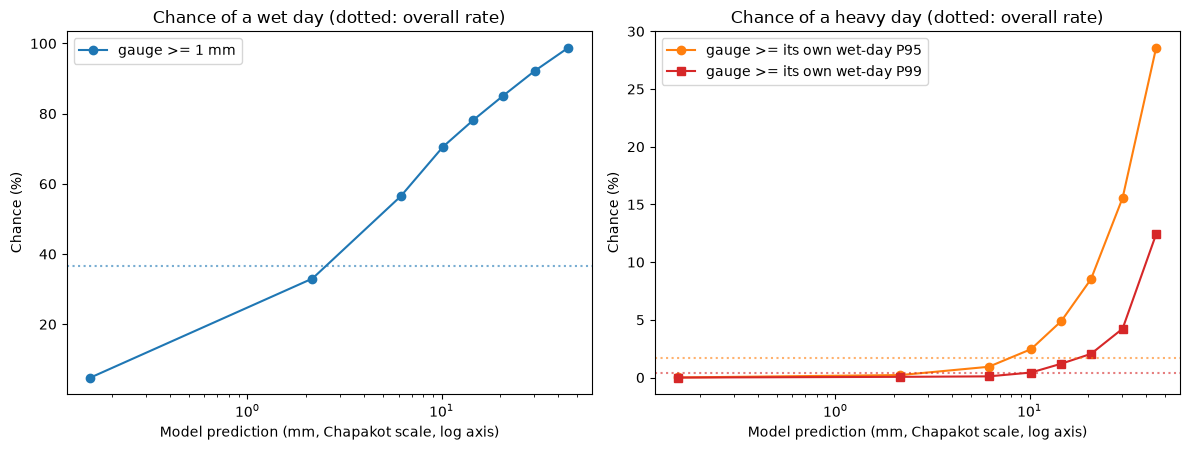

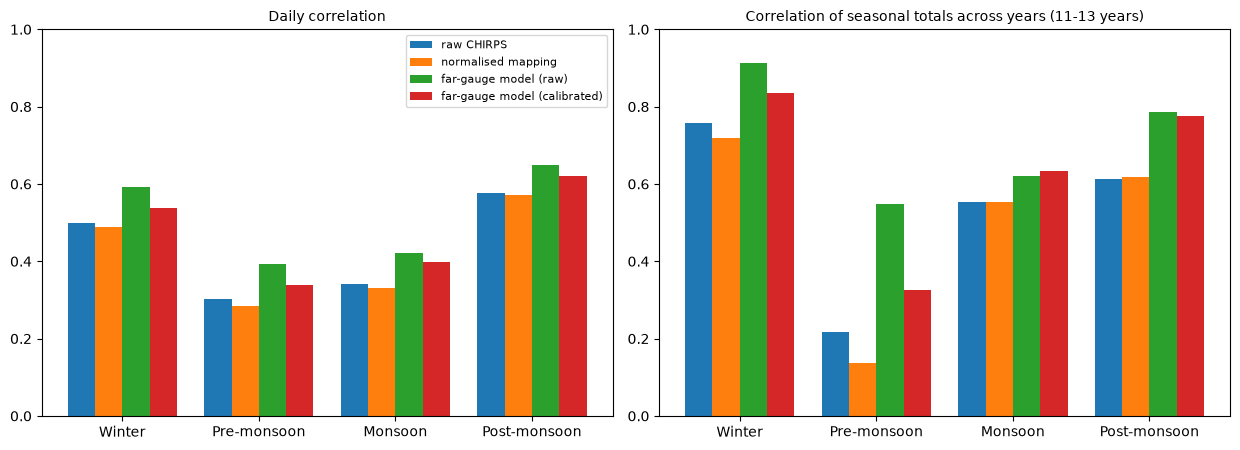

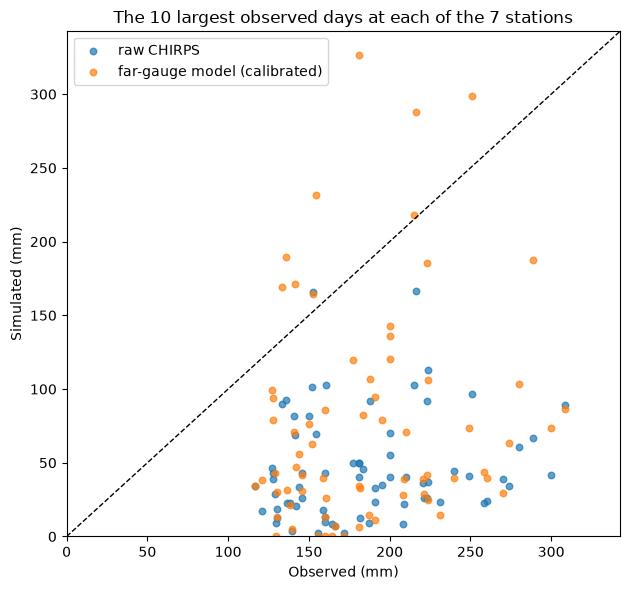

Far-gauge model (raw) minus raw CHIRPS, daily correlation, by season and group:
season      Winter  Pre-monsoon  Monsoon  Post-monsoon
group                                                 
dry-side 3    0.10         0.07     0.06          0.06
other 4       0.08         0.10     0.10          0.08
Cells where the model beats CHIRPS: 28 of 28

The 70 largest observed days:
                      output  median sim/obs  share >= half of observed  share >= observed
                  raw CHIRPS            0.19                       0.13               0.01
          normalised mapping            0.24                       0.24               0.09
       far-gauge model (raw)            0.18                       0.01               0.00
far-gauge model (calibrated)            0.29                       0.31               0.13

Saved: outputs/figures/fig5_reliability.png, fig6_seasonal_skill.png, fig7_largest_days.png


In [5]:
# ============================================================
# CELL 5 (06_evaluation_extremes): Figures for the write-up (reads saved files; nothing is re-tuned)
# What it does:
#   1) Figure 5: reliability by prediction size, from outputs/reliability_table.csv: chance that the
#      gauge read >= 1 mm (left panel), and >= its own wet-day P95 / P99 (right panel), against the
#      model's mean prediction in each of the 8 bins (mm at Chapakot's level); dotted lines show the
#      overall rate of each event
#   2) Figure 6: skill by season, from outputs/seasonal_scores.csv: daily correlation and correlation of
#      seasonal totals across years, four outputs, mean over the 7 stations
#   3) Figure 7: the 70 largest observed days (10 per station), from outputs/extremes_events.csv:
#      observed vs simulated rain for raw CHIRPS and the calibrated far-gauge model, with the 1:1 line
#   4) prints: the far-gauge gain in daily r (raw far-gauge model minus raw CHIRPS) by season for the
#      three dry-side stations and the other four; and, over the 70 events, the median simulated/observed
#      ratio and the share of events where the output reached at least half and at least the full
#      observed amount
#   figures go to outputs/figures/
# ============================================================
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

ROOT = Path.cwd().parent
OUT = ROOT / "outputs"
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)

# --- Figure 5: reliability ---
rel = pd.read_csv(OUT / "reliability_table.csv")
base = {c: (rel["n"] * rel[c]).sum() / rel["n"].sum()
        for c in ["P(>=1mm) %", "P(>=P95) %", "P(>=P99) %"]}
x = rel["model mean"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
ax.plot(x, rel["P(>=1mm) %"], "o-", color="C0", label="gauge >= 1 mm")
ax.axhline(base["P(>=1mm) %"], ls=":", color="C0", alpha=0.6)
ax.set_xscale("log")
ax.set_xlabel("Model prediction (mm, Chapakot scale, log axis)")
ax.set_ylabel("Chance (%)")
ax.set_title("Chance of a wet day (dotted: overall rate)")
ax.legend()
ax = axes[1]
ax.plot(x, rel["P(>=P95) %"], "o-", color="C1", label="gauge >= its own wet-day P95")
ax.plot(x, rel["P(>=P99) %"], "s-", color="C3", label="gauge >= its own wet-day P99")
ax.axhline(base["P(>=P95) %"], ls=":", color="C1", alpha=0.6)
ax.axhline(base["P(>=P99) %"], ls=":", color="C3", alpha=0.6)
ax.set_xscale("log")
ax.set_xlabel("Model prediction (mm, Chapakot scale, log axis)")
ax.set_ylabel("Chance (%)")
ax.set_title("Chance of a heavy day (dotted: overall rate)")
ax.legend()
plt.tight_layout()
fig.savefig(FIG / "fig5_reliability.png", dpi=150)
plt.show()

# --- Figure 6: skill by season ---
sc = pd.read_csv(OUT / "seasonal_scores.csv")
SEAS = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]
OUTS = ["CHIRPS", "QMrel", "FG raw", "FG+QM"]
NAMES = {"CHIRPS": "raw CHIRPS", "QMrel": "normalised mapping",
         "FG raw": "far-gauge model (raw)", "FG+QM": "far-gauge model (calibrated)"}
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for ax, col, title in ((axes[0], "r", "Daily correlation"),
                       (axes[1], "r_total", "Correlation of seasonal totals across years (11-13 years)")):
    t = sc.groupby(["season", "output"])[col].mean().unstack().loc[SEAS, OUTS]
    w = 0.2
    for j, o in enumerate(OUTS):
        ax.bar(np.arange(len(SEAS)) + (j - 1.5) * w, t[o], w, label=NAMES[o])
    ax.set_xticks(range(len(SEAS)))
    ax.set_xticklabels(SEAS)
    ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10)
axes[0].legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "fig6_seasonal_skill.png", dpi=150)
plt.show()

# --- Figure 7: the 70 largest observed days ---
ev = pd.read_csv(OUT / "extremes_events.csv")
fig, ax = plt.subplots(figsize=(6.4, 6))
for col, lab, c in (("CHIRPS", "raw CHIRPS", "C0"), ("FG+QM", "far-gauge model (calibrated)", "C1")):
    ax.scatter(ev["obs"], ev[col], s=22, alpha=0.7, color=c, label=lab)
mx = float(np.nanmax(ev[["obs", "CHIRPS", "FG+QM"]].to_numpy())) * 1.05
ax.plot([0, mx], [0, mx], "k--", lw=1)
ax.set_xlim(0, mx)
ax.set_ylim(0, mx)
ax.set_xlabel("Observed (mm)")
ax.set_ylabel("Simulated (mm)")
ax.set_title("The 10 largest observed days at each of the 7 stations")
ax.legend(loc="upper left")
plt.tight_layout()
fig.savefig(FIG / "fig7_largest_days.png", dpi=150)
plt.show()

# --- 4) checks ---
DRY = ["Kunchha", "Bandipur", "Damauli"]
g = sc[sc["output"].isin(["CHIRPS", "FG raw"])].pivot_table(
    index=["station", "season"], columns="output", values="r")
g["gain"] = g["FG raw"] - g["CHIRPS"]
g = g.reset_index()
g["group"] = np.where(g["station"].isin(DRY), "dry-side 3", "other 4")
print("Far-gauge model (raw) minus raw CHIRPS, daily correlation, by season and group:")
print(g.pivot_table(index="group", columns="season", values="gain").loc[:, SEAS].round(2).to_string())
print("Cells where the model beats CHIRPS:", int((g["gain"] > 0).sum()), "of", len(g))

rows = []
for col in ("CHIRPS", "QMrel", "FG raw", "FG+QM"):
    r = ev[col] / ev["obs"]
    rows.append({"output": NAMES[col], "median sim/obs": round(float(r.median()), 2),
                 "share >= half of observed": round(float((r >= 0.5).mean()), 2),
                 "share >= observed": round(float((r >= 1.0).mean()), 2)})
print("\nThe 70 largest observed days:")
print(pd.DataFrame(rows).to_string(index=False))
print("\nSaved: outputs/figures/fig5_reliability.png, fig6_seasonal_skill.png, fig7_largest_days.png")